# Etapa 5a · O professor fechado: uma LLM que só se alcança pela API

| | |
|---|---|
| **Pergunta** | Quão bem uma LLM fechada resolve a tarefa quando tudo o que se tem dela é o texto da resposta, quanto custa e quanto demora, e que rótulos ela deixa para o aluno? |
| **Entrada** | `entregas/01_dados/` (os dados), `entregas/02_avaliacao/` (linha de base), `entregas/04b_intencao/` (a rede do zero treinada com rótulos humanos) e as respostas da API, gravadas pelos comandos de `especialista/experimentos/etapa5a.py`. |
| **Entrega** | `entregas/05a_professor_fechado/`: o treino rotulado pela LLM, as respostas dela em `dev` e teste, as respostas brutas da API, latência e custo medidos. |
| **Pronto quando** | (1) todo pedido enviado tem uma resposta gravada, e as falhas estão contadas; (2) o professor está medido na régua, com intervalo, e comparado de forma pareada com as referências; (3) latência e custo vêm de medida, não de estimativa; (4) o treino rotulado está gravado no formato que a destilação lê. |

**O que é "fechada".** A LLM roda no provedor. Não há pesos, nem a probabilidade que ela dá a cada rótulo: só o texto da resposta. É o cenário de **caixa-preta** da destilação, em que o aluno aprende com rótulos rígidos (Etapa 6, aluno A). O cenário de caixa-branca, com uma LLM aberta rodando nesta máquina, é a Etapa 5b.

**A LLM.** Claude Haiku 5.5, o modelo mais barato da família, escolhido pelo custo. Não houve piloto para comparar jeitos de chamá-la: a configuração é a que estava definida de antemão, e isso entra nos limites da etapa.

**Artigos de apoio**

- Rótulo do professor como alvo do aluno: Hinton et al., *Distilling the Knowledge in a Neural Network* ([arXiv 1503.02531](https://arxiv.org/abs/1503.02531)).
- Destilação de LLMs, caixa-preta e caixa-branca: Xu et al., *A Survey on Knowledge Distillation of Large Language Models* ([arXiv 2402.13116](https://arxiv.org/abs/2402.13116)).
- O workflow que serve de esqueleto ao projeto: Ni et al., *From Large to Super-Tiny* ([arXiv 2504.13471](https://arxiv.org/abs/2504.13471)).
- Escolha dos exemplos do prompt pelos vizinhos mais próximos: Liu et al., *What Makes Good In-Context Examples for GPT-3?* ([arXiv 2101.06804](https://arxiv.org/abs/2101.06804)).
- LLMs em intenção e entidades: He & Garner, *Can ChatGPT Detect Intent? Evaluating Large Language Models for Spoken Language Understanding* ([arXiv 2305.13512](https://arxiv.org/abs/2305.13512)).
- Latência medida uma consulta por vez: Reddi et al., *MLPerf Inference Benchmark* ([arXiv 1911.02549](https://arxiv.org/abs/1911.02549)).

**Roteiro**

1. O cenário e o pedido
2. O que voltou da API
3. O professor na régua
4. Onde o professor erra
5. Os rótulos que o aluno vai receber
6. Latência
7. Custo
8. Entrega
9. Resposta

In [1]:
import json
import shutil
from collections import Counter
from datetime import date

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML, Markdown, display

from especialista import visual
from especialista.avaliacao import eficiencia, qualidade, resultados
from especialista.avaliacao.previsao import Previsao, carregar_previsoes, ouro, salvar_previsoes
from especialista.bio import spans_para_bio
from especialista.caminhos import ENTREGAS, RAIZ, entrega
from especialista.dados import massive
from especialista.experimentos import etapa5a
from especialista.modelos.linha_de_base import LinhaDeBase
from especialista.professores import claude, resposta
from especialista.professores.claude import Ajuste, ProfessorClaude
from especialista.professores.demonstracoes import Demonstracoes, montar_conjunto
from especialista.professores.rotulagem import ler_conjunto, rotular

visual.aplicar_estilo()
pd.set_option("display.max_colwidth", 200)

PASTA = entrega("05a_professor_fechado")
SEMENTES = (0, 1, 2)
PROFESSOR = "Claude Haiku 5.5"

particoes, rotulos = massive.carregar_entrega()
treino, dev, teste = (particoes[p] for p in ("train", "dev", "test"))
intents, tipos = rotulos["intents"], rotulos["slot_types"]
ouro_treino, ouro_dev, ouro_teste = ouro(treino), ouro(dev), ouro(teste)


def n(x):
    return f"{int(x):,}".replace(",", ".")


def num(x, casas=1):
    return f"{x:.{casas}f}".replace(".", ",")


def pts(x, casas=1):
    return num(100 * x, casas)


def dif(x):
    return f"{100 * x:+.1f}".replace(".", ",").replace("-", "−")


def usd(x, casas=2):
    return "US$ " + num(x, casas)


def com_intervalo(linha):
    return f"{dif(linha['diferenca'])} ({dif(linha['ic_min'])} a {dif(linha['ic_max'])})"


def valor_com_intervalo(linha):
    return f"{pts(linha['valor'])} ({pts(linha['ic_min'])} a {pts(linha['ic_max'])})"


def posicao(linha):
    """Onde B fica em relação a A numa comparação pareada B − A."""
    return "acima" if linha["ic_min"] > 0 else "abaixo" if linha["ic_max"] < 0 else "sem diferença distinguível"

## 1. O cenário e o pedido

**O cenário.** Uma equipe tem um assistente virtual, muitos pedidos de usuários guardados e **poucos** deles rotulados por pessoas. Ela quer um modelo pequeno e não tem como rotular tudo à mão. A LLM entra como rotuladora: vê os poucos exemplos rotulados e rotula os muitos.

No projeto, isso fica assim:

In [2]:
conjunto_demo = montar_conjunto(treino)
demos = Demonstracoes(conjunto_demo)
ajuste = Ajuste(**json.loads((etapa5a.pasta_das_respostas("train") / "ajuste.json").read_text(encoding="utf-8")))
professor = ProfessorClaude(demos, rotulos, ajuste)   # aqui só monta pedidos: nenhuma chamada sai deste notebook

por_intencao = conjunto_demo["intent"].value_counts()
pd.Series({
    "Pedidos de treino": n(len(treino)),
    "Rótulos humanos que a LLM vê (conjunto de demonstração)": f"{n(len(conjunto_demo))} ({pts(len(conjunto_demo) / len(treino))}% do treino)",
    "Exemplos por intenção no conjunto de demonstração": f"{por_intencao.max()} (mínimo {por_intencao.min()}, em intenções com menos de {por_intencao.max()} exemplos no treino)",
    "Exemplos que entram em cada pedido": f"os {ajuste.k} mais parecidos com o pedido",
    "Pedidos que a LLM rotula": f"{n(len(treino))} de treino, {n(len(dev))} de dev e {n(len(teste))} de teste",
}).rename("").to_frame()

,
Pedidos de treino,11.514
Rótulos humanos que a LLM vê (conjunto de demonstração),"299 (2,6% do treino)"
Exemplos por intenção no conjunto de demonstração,"5 (mínimo 4, em intenções com menos de 5 exemplos no treino)"
Exemplos que entram em cada pedido,os 10 mais parecidos com o pedido
Pedidos que a LLM rotula,"11.514 de treino, 2.033 de dev e 2.974 de teste"


Os rótulos humanos de `dev` e de teste nunca entram em prompt nenhum: servem só para medir. Ao rotular o treino, um pedido que pertence ao conjunto de demonstração nunca recebe a si mesmo como exemplo.

**O pedido.** Cada chamada tem duas partes. As **instruções** são fixas: a tarefa, as regras e as listas de 60 intenções e 55 tipos de entidade. A **mensagem** muda a cada pedido: os exemplos resolvidos mais parecidos e, no fim, o pedido a resolver. Abaixo, um pedido de `dev` como ele foi enviado.

In [3]:
exemplo = dev.iloc[50]
pedido = professor.pedido(exemplo.utt)
instrucoes = pedido["system"][0]["text"]
regras, listas = instrucoes.split("\n\nIntenções:\n")
print("INSTRUÇÕES (fixas, guardadas em cache pelo provedor)\n")
print(regras)
print(f"\nIntenções:\n{chr(10).join(listas.splitlines()[:3])}\n... ({len(intents)} intenções e {len(tipos)} tipos de entidade, um por linha)")

INSTRUÇÕES (fixas, guardadas em cache pelo provedor)

Você é o módulo de compreensão de um assistente virtual. O usuário fala português de Portugal.

Para cada pedido do usuário, identifique:
1. a intenção: a ação que o usuário quer. Escolha exatamente uma da lista de intenções.
2. as entidades: os trechos do pedido que são argumentos dessa ação. Cada entidade tem um tipo da lista de tipos de entidade.

Regras para as entidades:
- Copie o texto de cada entidade exatamente como está no pedido, palavra por palavra. Não corrija, não traduza, não complete.
- Uma entidade é um trecho contínuo do pedido. Não junte palavras que não estão lado a lado.
- Liste as entidades na ordem em que aparecem no pedido.
- Se o pedido não tiver nenhuma entidade, devolva a lista vazia.
- Nem toda palavra importante é uma entidade. Siga o critério dos exemplos resolvidos.

Use só as intenções e os tipos de entidade das listas abaixo.

Responda com um objeto JSON com os campos "intent" e "slots". Cada item de 

In [4]:
print("MENSAGEM (muda a cada pedido)\n")
print(pedido["messages"][0]["content"])
print("\nRESPOSTA DA LLM\n")
print(etapa5a.respostas("dev")[f"dev-{exemplo.id}"]["texto"])

MENSAGEM (muda a cada pedido)

Exemplos resolvidos, parecidos com o pedido:

Pedido: qual é o último email que recebi
Resposta: {"intent": "email_query", "slots": []}

Pedido: hey quero bilhetes de comboio para odivelas na quarta-feira
Resposta: {"intent": "transport_ticket", "slots": [{"type": "place_name", "text": "odivelas"}, {"type": "date", "text": "quarta-feira"}]}

Pedido: qual é a minha agenda hoje
Resposta: {"intent": "calendar_query", "slots": [{"type": "date", "text": "hoje"}]}

Pedido: tweet longo tempo de espera e empregados não profissionais
Resposta: {"intent": "social_post", "slots": [{"type": "media_type", "text": "tweet"}]}

Pedido: cancelar a reunião de quinta feira da próxima semana às duas da tarde
Resposta: {"intent": "calendar_remove", "slots": [{"type": "event_name", "text": "reunião"}, {"type": "date", "text": "quinta feira da próxima semana"}, {"type": "time", "text": "duas da tarde"}]}

Pedido: qual é o meu último email
Resposta: {"intent": "email_query", "sl

A LLM devolve o **texto** de cada entidade, não a posição dela. Achar a posição no pedido é trabalho do projeto (`professores/resposta.py`), com uma regra só: procurar a sequência de palavras no pedido, em ordem; o que não for encontrado é descartado e conta como erro.

**A configuração da chamada**

In [5]:
pd.Series({
    "Modelo": pedido["model"],
    "Formato da resposta": "JSON imposto na geração por um esquema: a intenção e os tipos só podem ser os das listas",
    "Raciocínio antes de responder": "ligado" if ajuste.raciocinio else "desligado",
    "Esforço": ajuste.esforco,
    "Temperatura": "não existe neste modelo: a API recusa o parâmetro",
    "Limite da resposta": f"{pedido['max_tokens']} tokens",
    "Cache": "as instruções fixas são marcadas para cache",
    "Como os pedidos foram enviados": "dev, teste e treino em lote (metade do preço, sem pressa); latência com chamadas diretas, uma por vez",
}).rename("").to_frame()

,
Modelo,claude-haiku-5-5
Formato da resposta,JSON imposto na geração por um esquema: a intenção e os tipos só podem ser os das listas
Raciocínio antes de responder,desligado
Esforço,low
Temperatura,não existe neste modelo: a API recusa o parâmetro
Limite da resposta,1024 tokens
Cache,as instruções fixas são marcadas para cache
Como os pedidos foram enviados,"dev, teste e treino em lote (metade do preço, sem pressa); latência com chamadas diretas, uma por vez"


**Duas leituras combinadas antes de olhar os números.**

1. **O professor acrescenta algo aos 299 rótulos?** A referência é a linha de base da Etapa 2 treinada **só com os 299 exemplos** que a LLM vê. Se, em `dev`, o exact match do professor não ficar acima dela com intervalo de 95% todo acima de zero, a LLM não traz nada além do que os rótulos já davam, e destilar dela não se justifica.
2. **Onde o professor fica em relação aos 11.514 rótulos humanos?** A referência é a rede do zero da Etapa 4b. Não é critério de aprovação: diz se o aluno que aprender com o professor parte de um teto mais alto ou mais baixo do que o de quem tem todos os rótulos humanos.

## 2. O que voltou da API

Cada resposta foi gravada em disco no momento em que chegou. Este notebook só lê esses arquivos.

In [6]:
dados_de = {"dev": dev, "test": teste, "train": treino}
nome_de = {"dev": "dev", "test": "teste", "train": "treino"}
lidos = {}
for conjunto, dados in dados_de.items():
    previsoes, diagnostico, registros = ler_conjunto(etapa5a.respostas(conjunto), dados, conjunto, intents, tipos)
    lidos[conjunto] = {"previsoes": previsoes, "diagnostico": diagnostico, "registros": registros}
claude_dev, claude_teste, claude_treino = (lidos[c]["previsoes"] for c in ("dev", "test", "train"))

linhas = []
for conjunto, lido in lidos.items():
    d, registros = lido["diagnostico"], lido["registros"]
    linhas.append({
        "conjunto": nome_de[conjunto],
        "pedidos": len(registros),
        "sem registro": d["sem_registro"],
        "sem resposta (erro, recusa ou corte)": d["sem_resposta"] - d["sem_registro"],
        "JSON ilegível": d["json_invalido"],
        "intenção fora da lista": d["intencao_fora_da_lista"],
        "entidades devolvidas": d["entidades"],
        "tipo fora da lista": d["tipo_fora_da_lista"],
        "texto que não está no pedido": d["texto_nao_encontrado"],
    })
leitura = pd.DataFrame(linhas).set_index("conjunto")
leitura.loc["total"] = leitura.sum()
paradas = Counter(r["parada"] or f"erro: {r['erro']}" for lido in lidos.values() for r in lido["registros"])
display(leitura.map(n))
print("Como cada resposta terminou:", ", ".join(f"{motivo}: {n(q)}" for motivo, q in paradas.most_common()))

,pedidos,sem registro,"sem resposta (erro, recusa ou corte)",JSON ilegível,intenção fora da lista,entidades devolvidas,tipo fora da lista,texto que não está no pedido
conjunto,,,,,,,,
dev,2.033,0,0,0,0,2.208,0,4
teste,2.974,0,0,0,0,3.152,0,9
treino,11.514,0,0,0,0,12.572,0,32
total,16.521,0,0,0,0,17.932,0,45


Como cada resposta terminou: end_turn: 16.521


In [7]:
total = leitura.loc["total"]
sem_uso = total["sem registro"] + total["sem resposta (erro, recusa ou corte)"] + total["JSON ilegível"]
perdidas = total["tipo fora da lista"] + total["texto que não está no pedido"]

fora_do_pedido = []
for linha, registro in zip(dev.itertuples(), lidos["dev"]["registros"]):
    if resposta.ler(registro["texto"], linha.utt, intents, tipos)[1]["texto_nao_encontrado"]:
        fora_do_pedido.append({"pedido": linha.utt, "resposta da LLM": registro["texto"]})

if sem_uso == 0:
    frase_das_falhas = f"Os {n(total['pedidos'])} pedidos voltaram com uma resposta aproveitável: nenhuma falha, recusa ou resposta cortada."
else:
    frase_das_falhas = (f"De {n(total['pedidos'])} pedidos, **{n(sem_uso)}** ficaram sem resposta aproveitável ({pts(sem_uso / total['pedidos'], 2)}%). "
                        "Na régua, cada um deles conta como erro.")
display(Markdown(f"""
**Leitura.**

- {frase_das_falhas}
- O esquema imposto na geração cumpriu o papel: {n(total['intenção fora da lista'])} intenções e {n(total['tipo fora da lista'])} tipos de entidade fora das listas.
- De {n(total['entidades devolvidas'])} entidades devolvidas, **{n(total['texto que não está no pedido'])}** ({pts(total['texto que não está no pedido'] / total['entidades devolvidas'], 2)}%) traziam um texto que não está no pedido palavra por palavra, e foram descartadas. É a perda própria de pedir texto em vez de posição.
"""))
if fora_do_pedido:
    print(f"Exemplos de dev em que o texto de alguma entidade não está no pedido ({len(fora_do_pedido)} no total):")
    display(pd.DataFrame(fora_do_pedido).head(5))


**Leitura.**

- Os 16.521 pedidos voltaram com uma resposta aproveitável: nenhuma falha, recusa ou resposta cortada.
- O esquema imposto na geração cumpriu o papel: 0 intenções e 0 tipos de entidade fora das listas.
- De 17.932 entidades devolvidas, **45** (0,25%) traziam um texto que não está no pedido palavra por palavra, e foram descartadas. É a perda própria de pedir texto em vez de posição.


Exemplos de dev em que o texto de alguma entidade não está no pedido (4 no total):


,pedido,resposta da LLM
0,vou precisar de levar guarda-chuva para o trabalho hoje,"{""intent"": ""weather_query"", ""slots"": [{""type"": ""weather_descriptor"", ""text"": ""chuva""}, {""type"": ""date"", ""text"": ""hoje""}]}"
1,vê se a pizza hut já tem o meu pedido a caminho,"{""intent"": ""takeaway_query"", ""slots"": [{""type"": ""food_type"", ""text"": ""pizza""}, {""type"": ""business_name"", ""text"": ""pizza hut""}]}"
2,preciso de guarda-chuva esta tarde,"{""intent"": ""weather_query"", ""slots"": [{""type"": ""weather_descriptor"", ""text"": ""chuva""}, {""type"": ""date"", ""text"": ""esta tarde""}]}"
3,por favor põe música popular na pandora,"{""intent"": ""play_music"", ""slots"": [{""type"": ""music_descriptor"", ""text"": ""popular""}, {""type"": ""music_genre"", ""text"": ""popular""}, {""type"": ""app_name"", ""text"": ""pandora""}]}"


## 3. O professor na régua

A mesma régua da Etapa 2, com os rótulos humanos como gabarito. Primeiro o professor sozinho, nas duas partições.

In [8]:
medida_dev, medida_teste = qualidade.intervalo(ouro_dev, claude_dev), qualidade.intervalo(ouro_teste, claude_teste)
pd.DataFrame({
    "dev (intervalo de 95%)": [valor_com_intervalo(l) for _, l in medida_dev.iterrows()],
    "teste (intervalo de 95%)": [valor_com_intervalo(l) for _, l in medida_teste.iterrows()],
}, index=medida_dev.index).rename(index=qualidade.NOMES)

,dev (intervalo de 95%),teste (intervalo de 95%)
Acurácia de intenção,"84,1 (82,6 a 85,6)","83,5 (82,1 a 84,7)"
Macro-F1 de intenção,"84,4 (82,4 a 86,4)","82,1 (80,3 a 84,7)"
Precisão de entidades,"65,3 (63,2 a 67,4)","62,5 (60,7 a 64,3)"
Recall de entidades,"72,0 (69,9 a 74,0)","70,0 (68,4 a 71,8)"
F1 de entidades,"68,5 (66,5 a 70,5)","66,1 (64,5 a 67,7)"
Exact match,"54,7 (52,6 a 57,0)","54,0 (52,3 a 55,7)"


Agora contra as referências. São três, e cada uma responde a uma pergunta diferente:

| Referência | Rótulos humanos que usa | O que a comparação diz |
|---|---|---|
| Linha de base com 299 rótulos | os mesmos 299 que a LLM vê | o que a LLM acrescenta aos rótulos que recebeu |
| Linha de base (Etapa 2) | 11.514 | a LLM contra o método mais simples com todos os rótulos |
| Rede do zero (Etapa 4b), 3 sementes | 11.514 | a LLM contra o melhor modelo do projeto até aqui |

In [9]:
base_299 = LinhaDeBase(caracteres=True).treinar(conjunto_demo)
base_299.nome = "Linha de base com 299 rótulos"
referencias = {}
for particao, dados in (("dev", dev), ("test", teste)):
    referencias[particao] = {
        "Linha de base com 299 rótulos": [base_299.prever(list(dados["utt"]))],
        "Linha de base com 11.514 rótulos": [carregar_previsoes(ENTREGAS / "02_avaliacao" / "previsoes" / f"linha_de_base_{particao}.parquet")[1]],
        "Rede do zero com 11.514 rótulos": [carregar_previsoes(ENTREGAS / "04b_intencao" / "previsoes" / f"semente_{s}_{particao}.parquet")[1] for s in SEMENTES],
    }
gabarito = {"dev": ouro_dev, "test": ouro_teste}
do_professor = {"dev": claude_dev, "test": claude_teste}
# sempre professor − referência, pareado: os mesmos sorteios do conjunto para os dois lados
contra = {p: {ref: qualidade.comparar_grupos(gabarito[p], grupo, [do_professor[p]]) for ref, grupo in referencias[p].items()} for p in ("dev", "test")}


def quadro(particao):
    colunas = {ref: tabela["a"].map(pts) for ref, tabela in contra[particao].items()}
    colunas[PROFESSOR] = next(iter(contra[particao].values()))["b"].map(pts)
    return pd.DataFrame(colunas).loc[list(qualidade.METRICAS)].rename(index=qualidade.NOMES)


print("Teste: valor de cada sistema (%)")
display(quadro("test"))
print("Teste: professor menos referência, em pontos percentuais (intervalo de 95%)")
pd.DataFrame({ref: [com_intervalo(l) for _, l in tabela.loc[list(qualidade.METRICAS)].iterrows()] for ref, tabela in contra["test"].items()},
             index=[qualidade.NOMES[m] for m in qualidade.METRICAS])

Teste: valor de cada sistema (%)


,Linha de base com 299 rótulos,Linha de base com 11.514 rótulos,Rede do zero com 11.514 rótulos,Claude Haiku 5.5
Acurácia de intenção,"47,8","84,6","84,4","83,5"
Macro-F1 de intenção,"47,7","81,4","82,8","82,1"
F1 de entidades,"35,6","47,8","73,6","66,1"
Exact match,"19,4","45,2","62,5","54,0"


Teste: professor menos referência, em pontos percentuais (intervalo de 95%)


,Linha de base com 299 rótulos,Linha de base com 11.514 rótulos,Rede do zero com 11.514 rótulos
Acurácia de intenção,"+35,6 (+33,8 a +37,5)","−1,1 (−2,5 a +0,2)","−0,9 (−2,2 a +0,3)"
Macro-F1 de intenção,"+34,4 (+32,4 a +37,0)","+0,7 (−1,8 a +3,5)","−0,7 (−2,6 a +1,5)"
F1 de entidades,"+30,5 (+28,6 a +32,5)","+18,3 (+16,4 a +20,3)","−7,6 (−9,1 a −5,9)"
Exact match,"+34,6 (+32,6 a +36,5)","+8,8 (+6,8 a +10,8)","−8,4 (−10,3 a −6,7)"


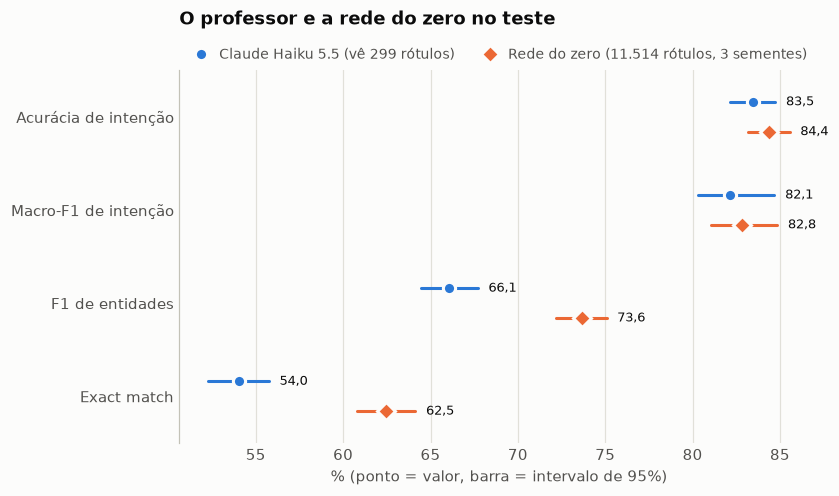

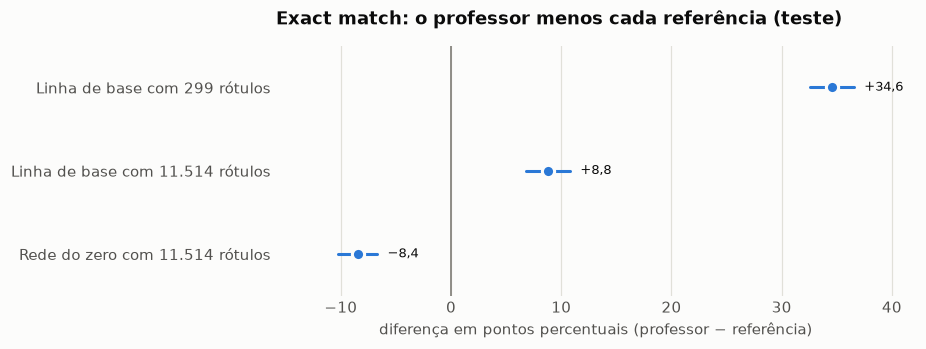

In [10]:
rede_teste = qualidade.intervalo_do_grupo(ouro_teste, referencias["test"]["Rede do zero com 11.514 rótulos"])
fig, ax = visual.pontos_com_intervalo(
    {
        f"{PROFESSOR} (vê 299 rótulos)": {qualidade.NOMES[m]: tuple(100 * medida_teste.loc[m, c] for c in ("valor", "ic_min", "ic_max")) for m in qualidade.METRICAS},
        "Rede do zero (11.514 rótulos, 3 sementes)": {qualidade.NOMES[m]: tuple(100 * rede_teste.loc[m, c] for c in ("valor", "ic_min", "ic_max")) for m in qualidade.METRICAS},
    },
    "O professor e a rede do zero no teste", "% (ponto = valor, barra = intervalo de 95%)",
)
visual.salvar(fig, PASTA, "professor_na_regua")
plt.show()

fig, ax = visual.diferencas_com_intervalo(
    {ref: tuple(100 * tabela.loc["exact_match", c] for c in ("diferenca", "ic_min", "ic_max")) for ref, tabela in contra["test"].items()},
    "Exact match: o professor menos cada referência (teste)", "diferença em pontos percentuais (professor − referência)",
)
visual.salvar(fig, PASTA, "professor_menos_referencias")
plt.show()

In [11]:
leitura_1 = contra["dev"]["Linha de base com 299 rótulos"].loc["exact_match"]
acrescenta = bool(leitura_1["ic_min"] > 0)
contra_rede = contra["test"]["Rede do zero com 11.514 rótulos"]
display(Markdown(f"""
**As duas leituras combinadas.**

1. **O professor acrescenta algo aos 299 rótulos?** {"Sim" if acrescenta else "Não"}. Em `dev`, o exact match do professor é {pts(leitura_1['b'])}% e o da linha de base treinada com os mesmos 299 rótulos é {pts(leitura_1['a'])}%: diferença de {com_intervalo(leitura_1)} pontos. {"O intervalo fica todo acima de zero." if acrescenta else "O intervalo não fica todo acima de zero."}
2. **Onde ele fica em relação aos 11.514 rótulos humanos?** No teste, contra a rede do zero: intenção {posicao(contra_rede.loc['intent_acc'])} ({com_intervalo(contra_rede.loc['intent_acc'])}), entidades {posicao(contra_rede.loc['slot_f1'])} ({com_intervalo(contra_rede.loc['slot_f1'])}), exact match {posicao(contra_rede.loc['exact_match'])} ({com_intervalo(contra_rede.loc['exact_match'])}).

**O que a literatura esperava.** He & Garner (arXiv 2305.13512) mediram LLMs nesta mesma família de tarefas: com poucos exemplos, as maiores chegam perto de modelos supervisionados em **intenção** e ficam atrás em **entidades**. É o mesmo desenho que aparece acima; a seção 4 mostra de onde vem a distância.
"""))


**As duas leituras combinadas.**

1. **O professor acrescenta algo aos 299 rótulos?** Sim. Em `dev`, o exact match do professor é 54,7% e o da linha de base treinada com os mesmos 299 rótulos é 20,2%: diferença de +34,5 (+32,3 a +37,1) pontos. O intervalo fica todo acima de zero.
2. **Onde ele fica em relação aos 11.514 rótulos humanos?** No teste, contra a rede do zero: intenção sem diferença distinguível (−0,9 (−2,2 a +0,3)), entidades abaixo (−7,6 (−9,1 a −5,9)), exact match abaixo (−8,4 (−10,3 a −6,7)).

**O que a literatura esperava.** He & Garner (arXiv 2305.13512) mediram LLMs nesta mesma família de tarefas: com poucos exemplos, as maiores chegam perto de modelos supervisionados em **intenção** e ficam atrás em **entidades**. É o mesmo desenho que aparece acima; a seção 4 mostra de onde vem a distância.


## 4. Onde o professor erra

Esta análise é feita em `dev`, para o teste continuar servindo só de medida final. Ela importa para a Etapa 6: o aluno vai aprender com estes erros.

### 4.1 Intenção ou entidades?

In [12]:
def acertos(gabarito, previsoes):
    intencao = np.array([p.intent == o.intent for o, p in zip(gabarito, previsoes)])
    entidades = np.array([set(p.slots) == set(o.slots) for o, p in zip(gabarito, previsoes)])
    return intencao, entidades


def reparticao(gabarito, previsoes):
    intencao, entidades = acertos(gabarito, previsoes)
    return pd.Series({
        "Tudo certo (exact match)": (intencao & entidades).mean(),
        "Só a intenção errada": (~intencao & entidades).mean(),
        "Só as entidades erradas": (intencao & ~entidades).mean(),
        "Intenção e entidades erradas": (~intencao & ~entidades).mean(),
    })


rede_dev = referencias["dev"]["Rede do zero com 11.514 rótulos"]
partes = pd.DataFrame({
    PROFESSOR: reparticao(ouro_dev, claude_dev),
    "Rede do zero (média de 3 sementes)": sum(reparticao(ouro_dev, p) for p in rede_dev) / len(rede_dev),
})
partes.map(lambda v: pts(v) + "%")

,Claude Haiku 5.5,Rede do zero (média de 3 sementes)
Tudo certo (exact match),"54,7%","62,6%"
Só a intenção errada,"7,3%","9,4%"
Só as entidades erradas,"29,4%","21,3%"
Intenção e entidades erradas,"8,6%","6,7%"


### 4.2 O que acontece com cada entidade

Cada entidade dos rótulos humanos cai em um destino: o sistema acertou, errou o limite (o trecho começa ou acaba em outro lugar), errou o tipo, errou os dois, ou não devolveu nada ali. "A mais" são entidades que o sistema devolveu onde os rótulos humanos não têm nenhuma.

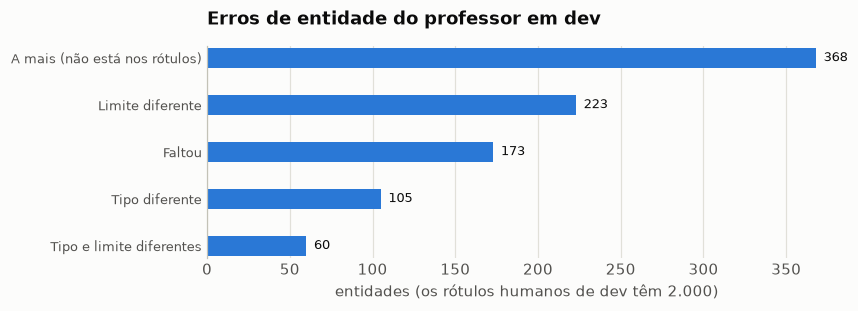

,Claude Haiku 5.5,Rede do zero (média de 3 sementes),"% das entidades dos rótulos, professor","% das entidades dos rótulos, rede"
Certa,1.439,1.531,"72,0%","76,5%"
Limite diferente,223,181,"11,2%","9,0%"
Tipo diferente,105,68,"5,2%","3,4%"
Tipo e limite diferentes,60,59,"3,0%","2,9%"
Faltou,173,162,"8,6%","8,1%"
A mais (não está nos rótulos),368,205,"18,4%","10,3%"


In [13]:
destinos = pd.DataFrame({
    PROFESSOR: qualidade.erros_de_entidade(ouro_dev, claude_dev),
    "Rede do zero (média de 3 sementes)": sum(qualidade.erros_de_entidade(ouro_dev, p) for p in rede_dev) / len(rede_dev),
})
entidades_em_dev = destinos[PROFESSOR][list(qualidade.DESTINOS)].sum()
nomes_dos_destinos = {
    "certa": "Certa", "limite diferente": "Limite diferente", "tipo diferente": "Tipo diferente",
    "tipo e limite diferentes": "Tipo e limite diferentes", "faltou": "Faltou", "a mais": "A mais (não está nos rótulos)",
}
erros_do_professor = destinos[PROFESSOR].drop("certa").rename(index=nomes_dos_destinos)
fig, ax = visual.barras_ranqueadas(
    erros_do_professor, "Erros de entidade do professor em dev", f"entidades (os rótulos humanos de dev têm {n(entidades_em_dev)})",
    destacar={nome: n(valor) for nome, valor in erros_do_professor.items()},
)
visual.salvar(fig, PASTA, "erros_de_entidade")
plt.show()

destinos.rename(index=nomes_dos_destinos).assign(**{
    "% das entidades dos rótulos, professor": lambda t: (t[PROFESSOR] / entidades_em_dev).map(lambda v: pts(v) + "%"),
    "% das entidades dos rótulos, rede": lambda t: (t["Rede do zero (média de 3 sementes)"] / entidades_em_dev).map(lambda v: pts(v) + "%"),
}).assign(**{PROFESSOR: lambda t: t[PROFESSOR].map(n), "Rede do zero (média de 3 sementes)": lambda t: t["Rede do zero (média de 3 sementes)"].map(lambda v: n(round(v)))})

In [14]:
por_tipo = qualidade.por_tipo_de_entidade(ouro_dev, claude_dev)
por_tipo_rede = qualidade.por_tipo_de_entidade(ouro_dev, rede_dev[0])
por_tipo["erros"] = (por_tipo["exemplos"] * (1 - por_tipo["recall"]) + por_tipo["previstas"] * (1 - por_tipo["precisao"])).round().astype(int)
piores_tipos = por_tipo.sort_values("erros", ascending=False).head(10)
print("Os 10 tipos de entidade com mais erros do professor em dev (entidades que faltaram mais entidades devolvidas erradas)")
pd.DataFrame({
    "nos rótulos humanos": piores_tipos["exemplos"].map(n),
    "devolvidas pelo professor": piores_tipos["previstas"].map(n),
    "precisão": piores_tipos["precisao"].map(pts),
    "recall": piores_tipos["recall"].map(pts),
    "F1 do professor": piores_tipos["f1"].map(pts),
    "F1 da rede (semente 0)": por_tipo_rede["f1"].reindex(piores_tipos.index).fillna(0).map(pts),
})

Os 10 tipos de entidade com mais erros do professor em dev (entidades que faltaram mais entidades devolvidas erradas)


,nos rótulos humanos,devolvidas pelo professor,precisão,recall,F1 do professor,F1 da rede (semente 0)
tipo,,,,,,
date,337,382,"70,4","79,8","74,8","82,4"
event_name,160,147,"69,4","63,7","66,4","70,1"
time,133,136,"64,0","65,4","64,7","73,1"
place_name,210,215,"80,0","81,9","80,9","79,1"
person,131,147,"72,8","81,7","77,0","78,2"
timeofday,48,46,"41,3","39,6","40,4","67,3"
food_type,50,69,"50,7","70,0","58,8","71,2"
weather_descriptor,58,51,"64,7","56,9","60,6","79,7"
news_topic,40,44,"50,0","55,0","52,4","58,7"


Alguns pedidos de `dev` em que o professor acertou a intenção e errou as entidades. Em cada par, a primeira linha são os rótulos humanos e a segunda é a resposta do professor.

In [15]:
intencao_ok, entidades_ok = acertos(ouro_dev, claude_dev)
so_entidades = np.flatnonzero(intencao_ok & ~entidades_ok)
escolhidos = np.random.default_rng(0).choice(so_entidades, size=min(6, len(so_entidades)), replace=False)
blocos = []
for i in sorted(escolhidos):
    linha = dev.iloc[i]
    tokens = list(linha.tokens)
    blocos.append(
        f'<div style="margin:0 0 14px 0;"><div style="font-size:12px;color:{visual.TINTA_SUAVE};">intenção: {linha.intent} · humano, depois professor</div>'
        + visual.html_bio(tokens, list(linha.tags))
        + visual.html_bio(tokens, spans_para_bio(list(claude_dev[i].slots), len(tokens)))
        + "</div>"
    )
HTML("".join(blocos))

### 4.3 Intenções trocadas

In [16]:
certa = np.array([o.intent for o in ouro_dev])
dada = np.array([p.intent for p in claude_dev])
trocas = pd.Series(Counter(zip(certa[certa != dada], dada[certa != dada]))).sort_values(ascending=False)
exemplos_da_troca = {par: dev["utt"].to_numpy()[(certa == par[0]) & (dada == par[1])][0] for par in trocas.index[:10]}
print(f"As 10 trocas de intenção mais frequentes do professor em dev ({n((certa != dada).sum())} erros de intenção no total)")
display(pd.DataFrame({
    "rótulo humano": [par[0] for par in trocas.index[:10]],
    "resposta do professor": [par[1] for par in trocas.index[:10]],
    "vezes": trocas.to_numpy()[:10],
    "um exemplo": [exemplos_da_troca[par] for par in trocas.index[:10]],
}))

f1_professor = qualidade.por_intencao(ouro_dev, claude_dev)
f1_rede = sum(qualidade.por_intencao(ouro_dev, p)["f1"] for p in rede_dev) / len(rede_dev)
piores = f1_professor.sort_values("f1").head(10)
print("As 10 intenções em que o professor vai pior em dev")
pd.DataFrame({
    "exemplos em dev": piores["exemplos"],
    "F1 do professor": piores["f1"].map(pts),
    "F1 da rede (média de 3 sementes)": f1_rede.reindex(piores.index).map(pts),
})

As 10 trocas de intenção mais frequentes do professor em dev (323 erros de intenção no total)


,rótulo humano,resposta do professor,vezes,um exemplo
0,general_quirky,qa_factoid,13,diz me algo sobre portugal
1,calendar_query,recommendation_events,9,existe algum programa para amanhã à noite
2,general_quirky,qa_definition,8,significado de uma palavra em particular
3,general_quirky,news_query,7,queres ouvir o que aconteceu hoje
4,news_query,qa_factoid,7,o que faz a câmara municipal do porto em relação aos sem-abrigo
5,calendar_set,calendar_query,7,assistir à festa antes da reunião
6,qa_factoid,recommendation_locations,7,onde o centro de convenção está situado
7,email_query,email_querycontact,6,verificar emails de carla
8,play_radio,play_music,6,abrir iheartradio e tocar rock
9,qa_definition,qa_factoid,6,o que sabes sobre a estátua da liberdade


As 10 intenções em que o professor vai pior em dev


,exemplos em dev,F1 do professor,F1 da rede (média de 3 sementes)
intent,,,
general_greet,2,"40,0","63,5"
cooking_query,2,"44,4","22,2"
general_quirky,105,"50,0","49,8"
music_settings,8,"54,5","65,8"
qa_factoid,90,"65,9","68,3"
email_querycontact,16,"68,3","76,8"
music_query,30,"69,6","71,9"
recommendation_events,26,"70,0","75,4"
music_likeness,16,"71,4","64,7"


### 4.4 Quanto o professor depende dos exemplos do prompt

Sem piloto, não há uma versão sem exemplos para comparar. O que dá para medir de graça: em quantos pedidos a intenção certa **aparece entre os 10 exemplos** do prompt, e como o professor se sai nos dois casos. A rede do zero entra como controle, porque pedidos sem exemplo parecido também tendem a ser os mais difíceis.

In [17]:
intencoes_no_prompt = [{e["intent"] for e in demos.mais_parecidos(texto, ajuste.k)} for texto in dev["utt"]]
aparece = np.array([o.intent in vistas for o, vistas in zip(ouro_dev, intencoes_no_prompt)])
acerto_rede = np.mean([[p.intent == o.intent for o, p in zip(ouro_dev, previsoes)] for previsoes in rede_dev], axis=0)
dependencia = pd.DataFrame([
    {
        "pedidos de dev": nome,
        "quantos": n(m.sum()),
        "parte de dev": pts(m.mean()) + "%",
        "acurácia de intenção do professor": pts(intencao_ok[m].mean()),
        "acurácia de intenção da rede do zero": pts(acerto_rede[m].mean()),
    }
    for nome, m in (("A intenção certa aparece entre os exemplos", aparece), ("A intenção certa não aparece", ~aparece))
]).set_index("pedidos de dev")
dependencia

,quantos,parte de dev,acurácia de intenção do professor,acurácia de intenção da rede do zero
pedidos de dev,,,,
A intenção certa aparece entre os exemplos,1.544,"75,9%","91,2","89,3"
A intenção certa não aparece,489,"24,1%","61,8","66,9"


## 5. Os rótulos que o aluno vai receber

O professor rotulou os 11.514 pedidos do treino. Como o treino tem rótulos humanos, dá para medir a qualidade desses rótulos diretamente. Em um caso real isso não existiria: só haveria a medida em uma amostra pequena, como `dev`.

In [18]:
medida_treino = qualidade.intervalo(ouro_treino, claude_treino)
concordancia = pd.DataFrame({
    "treino (os rótulos do aluno)": [valor_com_intervalo(l) for _, l in medida_treino.iterrows()],
    "dev": [valor_com_intervalo(l) for _, l in medida_dev.iterrows()],
    "teste": [valor_com_intervalo(l) for _, l in medida_teste.iterrows()],
}, index=medida_treino.index).rename(index=qualidade.NOMES)
print("Concordância do professor com os rótulos humanos, em % (intervalo de 95%)")
display(concordancia)

rotulado = rotular(treino, claude_treino, intents)
partes_treino = reparticao(ouro_treino, claude_treino)
print(f"Pedidos de treino sem rótulo aproveitável: {n((~rotulado['valido']).sum())} de {n(len(rotulado))}")
partes_treino.map(lambda v: pts(v) + "%").rename("parte do treino").to_frame()

Concordância do professor com os rótulos humanos, em % (intervalo de 95%)


,treino (os rótulos do aluno),dev,teste
Acurácia de intenção,"84,2 (83,6 a 84,9)","84,1 (82,6 a 85,6)","83,5 (82,1 a 84,7)"
Macro-F1 de intenção,"82,1 (81,2 a 83,1)","84,4 (82,4 a 86,4)","82,1 (80,3 a 84,7)"
Precisão de entidades,"64,1 (63,3 a 65,0)","65,3 (63,2 a 67,4)","62,5 (60,7 a 64,3)"
Recall de entidades,"71,3 (70,4 a 72,2)","72,0 (69,9 a 74,0)","70,0 (68,4 a 71,8)"
F1 de entidades,"67,5 (66,7 a 68,3)","68,5 (66,5 a 70,5)","66,1 (64,5 a 67,7)"
Exact match,"53,6 (52,8 a 54,5)","54,7 (52,6 a 57,0)","54,0 (52,3 a 55,7)"


Pedidos de treino sem rótulo aproveitável: 0 de 11.514


,parte do treino
Tudo certo (exact match),"53,6%"
Só a intenção errada,"7,8%"
Só as entidades erradas,"30,6%"
Intenção e entidades erradas,"8,0%"


In [19]:
humanas = pd.Series([o.intent for o in ouro_treino]).value_counts()
do_professor_treino = pd.Series([p.intent for p in claude_treino]).value_counts().reindex(humanas.index).fillna(0).astype(int)
desvio = (do_professor_treino - humanas).sort_values()
extremos = pd.concat([desvio.head(5), desvio.tail(5)])
print("Intenções que o professor usa menos (em cima) e mais (embaixo) do que os rótulos humanos, no treino")
display(pd.DataFrame({
    "nos rótulos humanos": humanas.reindex(extremos.index).map(n),
    "nos rótulos do professor": do_professor_treino.reindex(extremos.index).map(n),
    "diferença": extremos.map(lambda v: f"{v:+d}".replace("-", "−")),
}))

entidades_humanas = sum(len(o.slots) for o in ouro_treino)
entidades_do_professor = sum(len(p.slots) for p in claude_treino)
display(Markdown(f"""
**Leitura.**

- O aluno da Etapa 6 vai treinar com rótulos em que **{pts(partes_treino['Tudo certo (exact match)'])}%** dos pedidos estão inteiramente iguais aos humanos. Em {pts(partes_treino['Só as entidades erradas'] + partes_treino['Intenção e entidades erradas'])}% há pelo menos uma entidade diferente, e em {pts(partes_treino['Só a intenção errada'] + partes_treino['Intenção e entidades erradas'])}% a intenção é outra.
- A qualidade medida em `dev` ({pts(medida_dev.loc['exact_match', 'valor'])}% de exact match) e no teste ({pts(medida_teste.loc['exact_match', 'valor'])}%) é uma boa estimativa da qualidade dos rótulos do treino ({pts(medida_treino.loc['exact_match', 'valor'])}%): numa situação real, medir numa amostra pequena bastaria.
- O professor devolve {n(entidades_do_professor)} entidades no treino; os rótulos humanos têm {n(entidades_humanas)} ({dif(entidades_do_professor / entidades_humanas - 1)}%).
"""))

Intenções que o professor usa menos (em cima) e mais (embaixo) do que os rótulos humanos, no treino


,nos rótulos humanos,nos rótulos do professor,diferença
general_quirky,555,390,−165
calendar_set,810,738,−72
play_radio,283,233,−50
news_query,503,458,−45
calendar_query,566,528,−38
general_greet,25,62,+37
audio_volume_other,18,61,+43
music_query,154,198,+44
recommendation_events,190,258,+68
recommendation_locations,173,244,+71



**Leitura.**

- O aluno da Etapa 6 vai treinar com rótulos em que **53,6%** dos pedidos estão inteiramente iguais aos humanos. Em 38,6% há pelo menos uma entidade diferente, e em 15,8% a intenção é outra.
- A qualidade medida em `dev` (54,7% de exact match) e no teste (54,0%) é uma boa estimativa da qualidade dos rótulos do treino (53,6%): numa situação real, medir numa amostra pequena bastaria.
- O professor devolve 12.540 entidades no treino; os rótulos humanos têm 11.277 (+11,2%).


## 6. Latência

O mesmo protocolo dos modelos locais (Etapa 2): uma consulta por vez, 50 de aquecimento e 1.024 medidas, sorteadas de `dev`. O relógio cobre tudo: escolher os exemplos, a ida e a volta pela rede, a geração no provedor e a leitura da resposta. A medida vale para a rede de onde foi feita.

Uma primeira medição foi descartada. Ela rodou ao mesmo tempo que o envio dos lotes, que ocupou a mesma rede com dezenas de megabytes, e ficou presa quando a conexão oscilou. A medida abaixo foi refeita depois, com a rede livre.

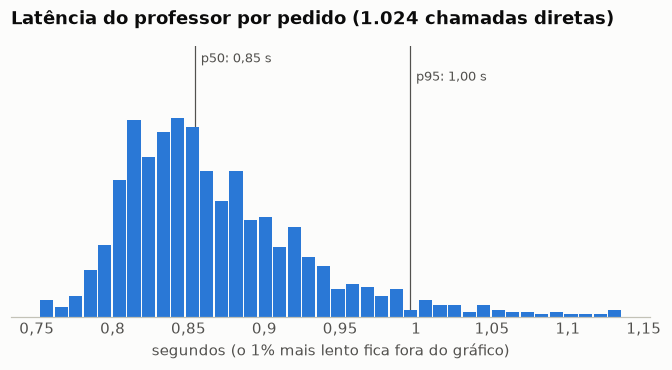

Chamadas medidas sem resposta aproveitável: 0 de 1024. Medido em 2026-11-17 21:33:41 -0300, de: rede do usuário, Brasil.
Cada chamada tem prazo de 60 s e até 2 novas tentativas automáticas em erro passageiro; o tempo delas entra na medida.


,Claude Haiku 5.5 (API),Rede do zero (1 núcleo de CPU)
p50 (ms),854,"1,20"
p90 (ms),953,"1,52"
p95 (ms),996,"1,60"
p99 (ms),1152,"1,90"
máximo (ms),1631,—


In [20]:
pasta_latencia = etapa5a.pasta_das_respostas("latencia")
tempos = np.load(pasta_latencia / "tempos_ms.npy")
meta_latencia = json.loads((pasta_latencia / "meta.json").read_text(encoding="utf-8"))
chamadas_medidas = etapa5a.chamadas("latencia")
assert len(chamadas_medidas) == len(tempos)
falhas_na_latencia = sum(r["texto"] is None for r in chamadas_medidas)
latencia = eficiencia.resumir_latencia(tempos)

rede_resultados = resultados.carregar(ENTREGAS / "04b_intencao").query("particao == 'test'").iloc[0]
p99 = latencia["latencia_p99_ms"]
fig, ax = visual.histograma(
    tempos[tempos <= p99] / 1000, f"Latência do professor por pedido ({n(len(tempos))} chamadas diretas)", "segundos (o 1% mais lento fica fora do gráfico)",
    marcas={f"p50: {num(latencia['latencia_p50_ms'] / 1000, 2)} s": latencia["latencia_p50_ms"] / 1000,
            f"p95: {num(latencia['latencia_p95_ms'] / 1000, 2)} s": latencia["latencia_p95_ms"] / 1000},
)
visual.salvar(fig, PASTA, "latencia")
plt.show()

vezes = latencia["latencia_p50_ms"] / rede_resultados["latencia_p50_ms"]
print(f"Chamadas medidas sem resposta aproveitável: {falhas_na_latencia} de {len(chamadas_medidas)}. Medido em {meta_latencia['quando']}, de: {meta_latencia['de_onde']}.")
print(f"Cada chamada tem prazo de {meta_latencia['prazo_por_chamada_s']:.0f} s e até {meta_latencia['novas_tentativas']} novas tentativas automáticas em erro passageiro; o tempo delas entra na medida.")
pd.DataFrame({
    PROFESSOR + " (API)": [num(latencia[f"latencia_{p}_ms"], 0) for p in ("p50", "p90", "p95", "p99")] + [num(tempos.max(), 0)],
    "Rede do zero (1 núcleo de CPU)": [num(rede_resultados[f"latencia_{p}_ms"], 2) for p in ("p50", "p90", "p95", "p99")] + ["—"],
}, index=["p50 (ms)", "p90 (ms)", "p95 (ms)", "p99 (ms)", "máximo (ms)"])

## 7. Custo

A API informa, em cada resposta, quantos tokens cobrou e de que tipo. O custo abaixo é a soma desses tokens pelo preço de lista. Não é estimativa de tamanho de prompt.

| Tipo de token | O que é | Preço por milhão |
|---|---|---|
| Entrada | o que foi enviado e não estava em cache | US$ 0,10 |
| Entrada lida do cache | as instruções fixas, quando o provedor já as tinha guardado | US$ 0,01 |
| Entrada escrita no cache | as instruções fixas, na vez em que são guardadas | US$ 0,125 |
| Saída | a resposta | US$ 0,50 |

Pedidos em lote custam metade em todos os tipos.

In [21]:
def por_pedido(registros, em_lote):
    "Médias por pedido respondido: tokens de entrada (todos os tipos), de saída, parte lida do cache e custo."
    respondidos = [r for r in registros if r["uso"]]
    entrada = np.array([r["uso"]["entrada"] + r["uso"]["cache_lido"] + r["uso"]["cache_escrito"] for r in respondidos])
    return {
        "tokens de entrada": entrada.mean(),
        "tokens de saída": np.mean([r["uso"]["saida"] for r in respondidos]),
        "pedidos com leitura de cache": np.mean([r["uso"]["cache_lido"] > 0 for r in respondidos]),
        "custo": np.mean([claude.custo(r["uso"], em_lote) for r in respondidos]),
        "custo sem cache": np.mean([claude.custo({"entrada": e, "saida": r["uso"]["saida"]}, em_lote) for e, r in zip(entrada, respondidos)]),
    }


em_lote = por_pedido([r for c in ("dev", "test", "train") for r in lidos[c]["registros"]], em_lote=True)
direto = por_pedido(chamadas_medidas, em_lote=False)
print("Médias por pedido")
pd.DataFrame({
    "Em lote (como o treino foi rotulado)": em_lote,
    "Direto (como um agente chamaria)": direto,
}).T.assign(**{
    "tokens de entrada": lambda t: t["tokens de entrada"].map(lambda v: n(round(v))),
    "tokens de saída": lambda t: t["tokens de saída"].map(lambda v: num(v, 1)),
    "pedidos com leitura de cache": lambda t: t["pedidos com leitura de cache"].map(lambda v: pts(v) + "%"),
    "custo por 1.000 pedidos": lambda t: t["custo"].map(lambda v: usd(1000 * v, 3)),
    "custo por 1.000 pedidos sem cache": lambda t: t["custo sem cache"].map(lambda v: usd(1000 * v, 3)),
}).drop(columns=["custo", "custo sem cache"])

Médias por pedido


,tokens de entrada,tokens de saída,pedidos com leitura de cache,custo por 1.000 pedidos,custo por 1.000 pedidos sem cache
Em lote (como o treino foi rotulado),3.237,"41,0","100,0%","US$ 0,057","US$ 0,172"
Direto (como um agente chamaria),3.235,"40,4","100,0%","US$ 0,114","US$ 0,344"


A conta da etapa soma os tokens de tudo o que foi chamado e tem registro. As chamadas diretas da latência incluem o aquecimento. Algumas chamadas ficaram **sem registro** (uma tentativa interrompida do teste de formato e a medição de latência descartada); para elas só dá para dar um teto, pelo custo médio de uma chamada direta.

In [22]:
diarios = [json.loads(linha) for arquivo in sorted(pasta_latencia.glob("diario_*.jsonl")) for linha in arquivo.open(encoding="utf-8")]
arquivo_sem_registro = pasta_latencia / "sem_registro.json"
sem_registro = json.loads(arquivo_sem_registro.read_text(encoding="utf-8")) if arquivo_sem_registro.exists() else []

uso = {
    "Teste de formato (chamadas diretas)": claude.resumir_uso(etapa5a.chamadas("teste")),
    "Lote de dev": claude.resumir_uso(lidos["dev"]["registros"], em_lote=True),
    "Lote de teste": claude.resumir_uso(lidos["test"]["registros"], em_lote=True),
    "Lote de treino": claude.resumir_uso(lidos["train"]["registros"], em_lote=True),
    "Latência (todas as chamadas diretas com registro)": claude.resumir_uso(diarios),
}
conta = pd.DataFrame(uso).T
gasto_registrado = float(conta["dolares"].sum())
custo_do_treino = uso["Lote de treino"]["dolares"]
chamadas_sem_registro = sum(item["chamadas_no_maximo"] for item in sem_registro)
teto_sem_registro = chamadas_sem_registro * direto["custo"]

conta_formatada = pd.DataFrame({
    "pedidos": conta["pedidos"].map(n),
    "entrada": conta["entrada"].map(n),
    "lida do cache": conta["cache_lido"].map(n),
    "escrita no cache": conta["cache_escrito"].map(n),
    "saída": conta["saida"].map(n),
    "custo": conta["dolares"].map(lambda v: usd(v, 4)),
})
vazio = {"entrada": "", "lida do cache": "", "escrita no cache": "", "saída": ""}
conta_formatada.loc["Total com registro"] = {"pedidos": n(conta["pedidos"].sum()), **vazio, "custo": usd(gasto_registrado, 4)}
conta_formatada.loc["Chamadas sem registro (teto)"] = {"pedidos": f"até {n(chamadas_sem_registro)}", **vazio, "custo": f"até {usd(teto_sem_registro, 4)}"}
print("Tokens cobrados e custo de cada parte da etapa")
display(conta_formatada)
fora_da_medida = len(diarios) - len(chamadas_medidas) - eficiencia.AQUECIMENTO
print(f"Chamadas diretas da latência: {n(len(chamadas_medidas))} medidas, {eficiencia.AQUECIMENTO} de aquecimento e {fora_da_medida} de uma execução interrompida logo no início.")
for item in sem_registro:
    print(f"Sem registro: {item['o_que']} (no máximo {n(item['chamadas_no_maximo'])} chamadas)")

Tokens cobrados e custo de cada parte da etapa


,pedidos,entrada,lida do cache,escrita no cache,saída,custo
Teste de formato (chamadas diretas),5,3.271,12.745,0,154,"US$ 0,0005"
Lote de dev,2.033,1.401.676,5.179.568,2.549,83.254,"US$ 0,1170"
Lote de teste,2.974,2.039.094,7.578.177,2.549,120.476,"US$ 0,1701"
Lote de treino,11.514,7.920.027,29.346.637,2.549,474.011,"US$ 0,6614"
Latência (todas as chamadas diretas com registro),1.080,740.981,2.752.920,0,43.599,"US$ 0,1234"
Total com registro,17.606,,,,,"US$ 1,0724"
Chamadas sem registro (teto),até 1.081,,,,,"até US$ 0,1236"


Chamadas diretas da latência: 1.024 medidas, 50 de aquecimento e 6 de uma execução interrompida logo no início.
Sem registro: primeira tentativa do teste de formato, interrompida antes de gravar (no máximo 5 chamadas)
Sem registro: primeira medição de latência, descartada: concorreu com o envio dos lotes pela mesma rede e foi encerrada sem gravar (no máximo 1.074 chamadas)
Sem registro: duas verificações de conexão com a API durante a instabilidade (pedidos mínimos) (no máximo 2 chamadas)


In [23]:
display(Markdown(f"""
**Leitura.**

- A etapa custou **{usd(gasto_registrado)}** em {n(conta['pedidos'].sum())} pedidos com registro, mais um teto de {usd(teto_sem_registro)} em chamadas sem registro. Rotular os {n(len(treino))} pedidos do treino custou {usd(custo_do_treino)}.
- Cada pedido leva em média {n(round(direto['tokens de entrada']))} tokens de entrada e {num(direto['tokens de saída'], 0)} de saída (o JSON da resposta). Quase todo o custo é entrada: as instruções com as listas de rótulos e os {ajuste.k} exemplos.
- Como um agente usaria (chamada direta, com as instruções em cache em {pts(direto['pedidos com leitura de cache'])}% das chamadas): **{usd(1000 * direto['custo'], 3)} por mil pedidos**, ou {usd(1e6 * direto['custo'], 0)} por milhão. Sem o cache seriam {usd(1000 * direto['custo sem cache'], 3)} por mil.
- Latência mediana de **{num(latencia['latencia_p50_ms'] / 1000, 2)} s** por pedido (p95 de {num(latencia['latencia_p95_ms'] / 1000, 2)} s). A rede do zero responde em {num(rede_resultados['latencia_p50_ms'], 1)} ms num núcleo de CPU: cerca de {n(round(vezes, -2))} vezes mais rápido.
"""))


**Leitura.**

- A etapa custou **US$ 1,07** em 17.606 pedidos com registro, mais um teto de US$ 0,12 em chamadas sem registro. Rotular os 11.514 pedidos do treino custou US$ 0,66.
- Cada pedido leva em média 3.235 tokens de entrada e 40 de saída (o JSON da resposta). Quase todo o custo é entrada: as instruções com as listas de rótulos e os 10 exemplos.
- Como um agente usaria (chamada direta, com as instruções em cache em 100,0% das chamadas): **US$ 0,114 por mil pedidos**, ou US$ 114 por milhão. Sem o cache seriam US$ 0,344 por mil.
- Latência mediana de **0,85 s** por pedido (p95 de 1,00 s). A rede do zero responde em 1,2 ms num núcleo de CPU: cerca de 700 vezes mais rápido.


## 8. Entrega

As respostas brutas da API vão para a entrega: elas custaram dinheiro, e com elas a etapa pode ser refeita sem nenhuma chamada nova.

In [24]:
# 1. O treino rotulado pelo professor, nas colunas que o treino da rede lê
rotulado.to_parquet(PASTA / "rotulos_treino.parquet", index=False)
conjunto_demo[["id", "intent", "utt", "tokens", "tags"]].to_parquet(PASTA / "demonstracoes.parquet", index=False)

# 2. As respostas do professor em dev e teste, no formato da régua
salvar_previsoes(PASTA / "previsoes" / "claude_dev.parquet", dev["id"], claude_dev)
salvar_previsoes(PASTA / "previsoes" / "claude_test.parquet", teste["id"], claude_teste)

# 3. As respostas brutas
for conjunto in (*etapa5a.CONJUNTOS_EM_LOTE, *etapa5a.CHAMADAS_DIRETAS):
    origem = etapa5a.PASTA / conjunto
    if origem.exists():
        shutil.copytree(origem, PASTA / "respostas" / conjunto, dirs_exist_ok=True)

# 4. A tabela de resultados
custo_por_mil = {"custo_por_mil_pedidos_usd": 1000 * direto["custo"], "custo_por_mil_pedidos_em_lote_usd": 1000 * em_lote["custo"]}
linhas_resultado = [
    resultados.registrar(f"{PROFESSOR} ({ajuste.k} exemplos de {len(conjunto_demo)} rótulos)", particao, gabarito[particao], do_professor[particao],
                         tempos_ms=tempos, modelo=claude.MODELO, **custo_por_mil)
    for particao in ("dev", "test")
] + [
    resultados.registrar(base_299.nome, particao, gabarito[particao], referencias[particao]["Linha de base com 299 rótulos"][0], parametros=base_299.parametros)
    for particao in ("dev", "test")
]
resultados.salvar(linhas_resultado, PASTA)
pd.concat({f"{p} · {ref}": t.loc[list(qualidade.METRICAS)] for p in ("dev", "test") for ref, t in contra[p].items()},
          names=["comparacao", "metrica"]).to_csv(PASTA / "comparacoes.csv")

# 5. Custo e configuração
(PASTA / "custo.json").write_text(json.dumps({
    "moeda": "USD", "precos_por_milhao_de_tokens": claude.PRECO, "desconto_do_lote": claude.DESCONTO_DO_LOTE,
    "partes": uso, "total_com_registro": gasto_registrado,
    "sem_registro": sem_registro, "teto_das_chamadas_sem_registro": teto_sem_registro,
    "por_pedido_em_lote": em_lote, "por_pedido_direto": direto,
}, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
(PASTA / "configuracao.json").write_text(json.dumps({
    "etapa": "05a_professor_fechado", "gerado_em": date.today().isoformat(), "modelo": claude.MODELO, "ajuste": ajuste.como_dict(),
    "max_tokens": claude.MAX_TOKENS, "conjunto_de_demonstracao": {"exemplos": len(conjunto_demo), "por_intencao": int(por_intencao.max()), "semente": 0},
    "piloto": "não houve: a configuração não foi comparada com alternativas",
    "latencia": meta_latencia,
}, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
(PASTA / "pedido_de_exemplo.md").write_text(
    f"# Um pedido como foi enviado ao {PROFESSOR}\n\n## Instruções (fixas)\n\n```\n{instrucoes}\n```\n\n## Mensagem\n\n```\n{pedido['messages'][0]['content']}\n```\n\n"
    f"## Esquema da resposta\n\n```json\n{json.dumps(pedido['output_config']['format']['schema'], ensure_ascii=False)}\n```\n", encoding="utf-8")

relido = pd.read_parquet(PASTA / "rotulos_treino.parquet")
relido_ok = [Previsao.de_tags(i, list(t)) for i, t in zip(relido["intent"], relido["tags"])] == claude_treino
print("Treino rotulado relido do disco reproduz as respostas do professor:", "sim" if relido_ok else "NÃO")
relido.head(3)

Treino rotulado relido do disco reproduz as respostas do professor: sim


,id,utt,tokens,intent,tags,valido
0,1,acorda-me às nove da manhã na sexta-feira,"[acorda-me, às, nove, da, manhã, na, sexta-feira]",alarm_set,"[O, O, B-time, I-time, I-time, O, B-date]",True
1,2,accionar um alarme durante duas horas a partir de agora,"[accionar, um, alarme, durante, duas, horas, a, partir, de, agora]",alarm_set,"[O, O, O, O, B-time, I-time, O, O, O, O]",True
2,4,olly não fales,"[olly, não, fales]",audio_volume_mute,"[O, O, O]",True


### Critério de pronto

In [25]:
sem_registro = int(leitura.loc["total", "sem registro"])
pronto = pd.Series({
    f"Todo pedido enviado tem resposta gravada ({n(total['pedidos'])} pedidos; {n(sem_uso)} sem resposta aproveitável, contados como erro)": sem_registro == 0,
    "Professor medido na régua, com intervalo, e comparado de forma pareada com as três referências": all(len(contra[p]) == 3 for p in ("dev", "test")),
    f"Latência medida em {n(len(tempos))} chamadas e custo somado dos tokens cobrados": len(tempos) >= eficiencia.CONSULTAS and gasto_registrado > 0,
    "Treino rotulado gravado no formato que a destilação lê": bool(relido_ok and len(relido) == len(treino)),
}).map({True: "sim", False: "NÃO"}).rename("atendido").to_frame()
assert (pronto["atendido"] == "sim").all()
pronto

,atendido
"Todo pedido enviado tem resposta gravada (16.521 pedidos; 0 sem resposta aproveitável, contados como erro)",sim
"Professor medido na régua, com intervalo, e comparado de forma pareada com as três referências",sim
Latência medida em 1.024 chamadas e custo somado dos tokens cobrados,sim
Treino rotulado gravado no formato que a destilação lê,sim


## 9. Resposta

O resumo abaixo é gerado a partir dos números calculados neste notebook e gravado em `entregas/05a_professor_fechado/RESUMO.md`.

In [26]:
tabela_teste = "\n".join(
    f"| {qualidade.NOMES[m]} | {valor_com_intervalo(medida_teste.loc[m])} | "
    + " | ".join(f"{pts(t.loc[m, 'a'])} · {com_intervalo(t.loc[m])}" for t in contra["test"].values()) + " |"
    for m in qualidade.METRICAS
)
tabela_destinos = "\n".join(
    f"| {nomes_dos_destinos[d]} | {n(destinos.loc[d, PROFESSOR])} ({pts(destinos.loc[d, PROFESSOR] / entidades_em_dev)}%) | {n(round(destinos.loc[d, 'Rede do zero (média de 3 sementes)']))} ({pts(destinos.loc[d, 'Rede do zero (média de 3 sementes)'] / entidades_em_dev)}%) |"
    for d in destinos.index
)
tabela_rotulos = "\n".join(
    f"| {qualidade.NOMES[m]} | {valor_com_intervalo(medida_treino.loc[m])} | {valor_com_intervalo(medida_dev.loc[m])} | {valor_com_intervalo(medida_teste.loc[m])} |"
    for m in qualidade.METRICAS
)
tabela_custo = "\n".join(f"| {parte} | {linha['pedidos']} | {linha['custo']} |" for parte, linha in conta_formatada.iterrows())
troca_1 = trocas.index[0]

if acrescenta:
    primeira = (f"**Vale como professor**: em `dev`, o exact match dele ({pts(leitura_1['b'])}%) fica {com_intervalo(leitura_1)} pontos acima do da linha de base "
                f"treinada com os mesmos 299 rótulos ({pts(leitura_1['a'])}%).")
else:
    primeira = (f"**Não passou na primeira leitura**: em `dev`, o exact match dele ({pts(leitura_1['b'])}%) não fica acima do da linha de base "
                f"treinada com os mesmos 299 rótulos ({pts(leitura_1['a'])}%): {com_intervalo(leitura_1)} pontos.")

resumo = f"""# Etapa 5a · O professor fechado: resumo da entrega

**Pergunta.** Quão bem uma LLM fechada resolve a tarefa quando tudo o que se tem dela é o texto da resposta, quanto custa e quanto demora, e que rótulos ela deixa para o aluno?

**Resposta.** O {PROFESSOR}, vendo {len(conjunto_demo)} rótulos humanos como exemplos, faz no teste {pts(medida_teste.loc['intent_acc', 'valor'])}% de acurácia de intenção, {pts(medida_teste.loc['slot_f1', 'valor'])}% de F1 de entidades e {pts(medida_teste.loc['exact_match', 'valor'])}% de exact match. {primeira} Contra a rede do zero treinada com os {n(len(treino))} rótulos humanos, no teste, ele fica {posicao(contra_rede.loc['intent_acc'])} em intenção ({com_intervalo(contra_rede.loc['intent_acc'])}), {posicao(contra_rede.loc['slot_f1'])} em entidades ({com_intervalo(contra_rede.loc['slot_f1'])}) e {posicao(contra_rede.loc['exact_match'])} em exact match ({com_intervalo(contra_rede.loc['exact_match'])}). Cada resposta leva {num(latencia['latencia_p50_ms'] / 1000, 2)} s (mediana) e custa {usd(1000 * direto['custo'], 3)} por mil pedidos; a rede do zero responde em {num(rede_resultados['latencia_p50_ms'], 1)} ms. O treino rotulado por ele concorda inteiramente com os rótulos humanos em {pts(medida_treino.loc['exact_match', 'valor'])}% dos pedidos, e custou {usd(custo_do_treino)}.

O desenho (intenção perto de um modelo supervisionado, entidades atrás) é o que He & Garner ([arXiv 2305.13512](https://arxiv.org/abs/2305.13512)) relatam para LLMs com poucos exemplos.

## O cenário

- A LLM vê {len(conjunto_demo)} exemplos rotulados por humanos ({pts(len(conjunto_demo) / len(treino))}% do treino, até {int(por_intencao.max())} por intenção). Em cada pedido entram os {ajuste.k} mais parecidos.
- Modelo `{claude.MODELO}`, raciocínio {"ligado" if ajuste.raciocinio else "desligado"}, esforço `{ajuste.esforco}`, resposta em JSON imposta por esquema.
- {n(total['pedidos'])} pedidos rotulados em lote: {n(len(treino))} de treino, {n(len(dev))} de dev, {n(len(teste))} de teste.

## Qualidade no teste

Cada coluna de referência traz o valor da referência e, depois do ponto, a diferença professor − referência com intervalo de 95%.

| Métrica | {PROFESSOR} (intervalo de 95%) | {" | ".join(contra["test"])} |
|---|---|---|---|---|
{tabela_teste}

![O professor e a rede do zero](figuras/professor_na_regua.png)

![Professor menos referências](figuras/professor_menos_referencias.png)

## O que voltou da API

- Sem resposta aproveitável: {n(sem_uso)} de {n(total['pedidos'])} pedidos ({pts(sem_uso / total['pedidos'], 2)}%).
- Intenções fora da lista: {n(total['intenção fora da lista'])}. Tipos de entidade fora da lista: {n(total['tipo fora da lista'])}.
- Entidades com texto que não está no pedido, descartadas: {n(total['texto que não está no pedido'])} de {n(total['entidades devolvidas'])} ({pts(total['texto que não está no pedido'] / total['entidades devolvidas'], 2)}%).

## Onde o professor erra (dev)

Em dev, o professor acerta tudo em {pts(partes.loc['Tudo certo (exact match)', PROFESSOR])}% dos pedidos, erra só as entidades em {pts(partes.loc['Só as entidades erradas', PROFESSOR])}%, só a intenção em {pts(partes.loc['Só a intenção errada', PROFESSOR])}% e as duas em {pts(partes.loc['Intenção e entidades erradas', PROFESSOR])}%.

| Destino de cada entidade dos rótulos humanos | {PROFESSOR} | Rede do zero (média de 3 sementes) |
|---|---|---|
{tabela_destinos}

![Erros de entidade](figuras/erros_de_entidade.png)

- A troca de intenção mais frequente: `{troca_1[0]}` respondida como `{troca_1[1]}` ({trocas.iloc[0]} vezes em dev).
- Quando a intenção certa aparece entre os {ajuste.k} exemplos do prompt ({dependencia.iloc[0]['parte de dev']} de dev), o professor acerta a intenção em {dependencia.iloc[0]['acurácia de intenção do professor']}% dos pedidos; quando não aparece, em {dependencia.iloc[1]['acurácia de intenção do professor']}%. A rede do zero faz {dependencia.iloc[0]['acurácia de intenção da rede do zero']}% e {dependencia.iloc[1]['acurácia de intenção da rede do zero']}% nos mesmos grupos.

## Os rótulos do aluno

Concordância do professor com os rótulos humanos, em % (intervalo de 95%):

| Métrica | Treino | Dev | Teste |
|---|---|---|---|
{tabela_rotulos}

- Pedidos de treino sem rótulo aproveitável: {n((~rotulado['valido']).sum())}.
- A medida em `dev` antecipa bem a qualidade dos rótulos do treino.

## Latência e custo

- Latência por pedido, uma chamada por vez, {n(len(tempos))} chamadas: p50 {num(latencia['latencia_p50_ms'] / 1000, 2)} s, p95 {num(latencia['latencia_p95_ms'] / 1000, 2)} s, p99 {num(latencia['latencia_p99_ms'] / 1000, 2)} s. Medida em {meta_latencia['quando'][:10]}, de: {meta_latencia['de_onde']}.
- Por pedido: {n(round(direto['tokens de entrada']))} tokens de entrada e {num(direto['tokens de saída'], 0)} de saída, em média.
- Chamada direta: {usd(1000 * direto['custo'], 3)} por mil pedidos ({usd(1000 * direto['custo sem cache'], 3)} sem cache). Em lote: {usd(1000 * em_lote['custo'], 3)} por mil, com leitura de cache em {pts(em_lote['pedidos com leitura de cache'])}% dos pedidos.

![Latência](figuras/latencia.png)

| Parte da etapa | Pedidos | Custo |
|---|---|---|
{tabela_custo}

Envio dos lotes: o treino inteiro num único envio (84 MB) foi recusado pelo servidor; os lotes foram enviados em partes de {n(etapa5a.TAMANHO_DO_ENVIO)} pedidos. Nenhum pedido foi cobrado em dobro.

## Limites

- **Sem piloto.** A configuração ({ajuste.k} exemplos, raciocínio {"ligado" if ajuste.raciocinio else "desligado"}) não foi comparada com alternativas. Mais exemplos, raciocínio ligado ou um modelo maior poderiam dar um professor melhor, a outro custo.
- **Um modelo, uma execução.** A API não tem temperatura neste modelo e a saída não é garantidamente determinística; cada pedido foi feito uma vez.
- **A latência é de uma rede e de um horário.** Inclui a ida e a volta até o provedor.
- **O custo é o preço de lista** em {date.today().strftime('%d/%m/%Y')}, somado dos tokens que a API informou. As chamadas sem registro entram só como teto ({usd(teto_sem_registro)}); o valor exato está no painel de uso da conta.
- **A latência foi medida duas vezes.** A primeira medição concorreu com o envio dos lotes e foi descartada; vale a segunda, feita com a rede livre.
- **O modelo pode conhecer o MASSIVE.** O conjunto é público desde 2022 e pode estar nos dados de treino da LLM. Isso não se mede daqui.

## Para a Etapa 6

- O aluno A treina com `rotulos_treino.parquet`: as colunas que o treino da rede lê (`id`, `utt`, `tokens`, `intent`, `tags`), com `intent` e `tags` do professor. A coluna `valido` marca os pedidos sem rótulo aproveitável.
- A referência "sem LLM" do cenário é um modelo treinado só com os {len(conjunto_demo)} rótulos de `demonstracoes.parquet`.

## Arquivos

| Arquivo | Conteúdo |
|---|---|
| `rotulos_treino.parquet` | O treino rotulado pelo professor |
| `demonstracoes.parquet` | Os {len(conjunto_demo)} exemplos com rótulo humano que a LLM vê |
| `previsoes/` | As respostas do professor em dev e teste, no formato da régua |
| `respostas/` | As respostas brutas da API, com os tokens cobrados; a latência medida |
| `resultados.csv`, `comparacoes.csv` | O professor e a linha de base com {len(conjunto_demo)} rótulos na régua; cada comparação pareada |
| `custo.json`, `configuracao.json` | Tokens e dólares por parte; modelo e ajustes da chamada |
| `pedido_de_exemplo.md` | Um pedido completo, como foi enviado |
| `figuras/` | Os gráficos deste notebook |
| `05a_professor_fechado.html` | Este notebook executado, para leitura |
"""
(PASTA / "RESUMO.md").write_text(resumo, encoding="utf-8")
display(Markdown(resumo))

# Etapa 5a · O professor fechado: resumo da entrega

**Pergunta.** Quão bem uma LLM fechada resolve a tarefa quando tudo o que se tem dela é o texto da resposta, quanto custa e quanto demora, e que rótulos ela deixa para o aluno?

**Resposta.** O Claude Haiku 5.5, vendo 299 rótulos humanos como exemplos, faz no teste 83,5% de acurácia de intenção, 66,1% de F1 de entidades e 54,0% de exact match. **Vale como professor**: em `dev`, o exact match dele (54,7%) fica +34,5 (+32,3 a +37,1) pontos acima do da linha de base treinada com os mesmos 299 rótulos (20,2%). Contra a rede do zero treinada com os 11.514 rótulos humanos, no teste, ele fica sem diferença distinguível em intenção (−0,9 (−2,2 a +0,3)), abaixo em entidades (−7,6 (−9,1 a −5,9)) e abaixo em exact match (−8,4 (−10,3 a −6,7)). Cada resposta leva 0,85 s (mediana) e custa US$ 0,114 por mil pedidos; a rede do zero responde em 1,2 ms. O treino rotulado por ele concorda inteiramente com os rótulos humanos em 53,6% dos pedidos, e custou US$ 0,66.

O desenho (intenção perto de um modelo supervisionado, entidades atrás) é o que He & Garner ([arXiv 2305.13512](https://arxiv.org/abs/2305.13512)) relatam para LLMs com poucos exemplos.

## O cenário

- A LLM vê 299 exemplos rotulados por humanos (2,6% do treino, até 5 por intenção). Em cada pedido entram os 10 mais parecidos.
- Modelo `claude-haiku-5-5`, raciocínio desligado, esforço `low`, resposta em JSON imposta por esquema.
- 16.521 pedidos rotulados em lote: 11.514 de treino, 2.033 de dev, 2.974 de teste.

## Qualidade no teste

Cada coluna de referência traz o valor da referência e, depois do ponto, a diferença professor − referência com intervalo de 95%.

| Métrica | Claude Haiku 5.5 (intervalo de 95%) | Linha de base com 299 rótulos | Linha de base com 11.514 rótulos | Rede do zero com 11.514 rótulos |
|---|---|---|---|---|
| Acurácia de intenção | 83,5 (82,1 a 84,7) | 47,8 · +35,6 (+33,8 a +37,5) | 84,6 · −1,1 (−2,5 a +0,2) | 84,4 · −0,9 (−2,2 a +0,3) |
| Macro-F1 de intenção | 82,1 (80,3 a 84,7) | 47,7 · +34,4 (+32,4 a +37,0) | 81,4 · +0,7 (−1,8 a +3,5) | 82,8 · −0,7 (−2,6 a +1,5) |
| F1 de entidades | 66,1 (64,5 a 67,7) | 35,6 · +30,5 (+28,6 a +32,5) | 47,8 · +18,3 (+16,4 a +20,3) | 73,6 · −7,6 (−9,1 a −5,9) |
| Exact match | 54,0 (52,3 a 55,7) | 19,4 · +34,6 (+32,6 a +36,5) | 45,2 · +8,8 (+6,8 a +10,8) | 62,5 · −8,4 (−10,3 a −6,7) |

![O professor e a rede do zero](figuras/professor_na_regua.png)

![Professor menos referências](figuras/professor_menos_referencias.png)

## O que voltou da API

- Sem resposta aproveitável: 0 de 16.521 pedidos (0,00%).
- Intenções fora da lista: 0. Tipos de entidade fora da lista: 0.
- Entidades com texto que não está no pedido, descartadas: 45 de 17.932 (0,25%).

## Onde o professor erra (dev)

Em dev, o professor acerta tudo em 54,7% dos pedidos, erra só as entidades em 29,4%, só a intenção em 7,3% e as duas em 8,6%.

| Destino de cada entidade dos rótulos humanos | Claude Haiku 5.5 | Rede do zero (média de 3 sementes) |
|---|---|---|
| Certa | 1.439 (72,0%) | 1.531 (76,5%) |
| Limite diferente | 223 (11,2%) | 181 (9,0%) |
| Tipo diferente | 105 (5,2%) | 68 (3,4%) |
| Tipo e limite diferentes | 60 (3,0%) | 59 (2,9%) |
| Faltou | 173 (8,6%) | 162 (8,1%) |
| A mais (não está nos rótulos) | 368 (18,4%) | 205 (10,3%) |

![Erros de entidade](figuras/erros_de_entidade.png)

- A troca de intenção mais frequente: `general_quirky` respondida como `qa_factoid` (13 vezes em dev).
- Quando a intenção certa aparece entre os 10 exemplos do prompt (75,9% de dev), o professor acerta a intenção em 91,2% dos pedidos; quando não aparece, em 61,8%. A rede do zero faz 89,3% e 66,9% nos mesmos grupos.

## Os rótulos do aluno

Concordância do professor com os rótulos humanos, em % (intervalo de 95%):

| Métrica | Treino | Dev | Teste |
|---|---|---|---|
| Acurácia de intenção | 84,2 (83,6 a 84,9) | 84,1 (82,6 a 85,6) | 83,5 (82,1 a 84,7) |
| Macro-F1 de intenção | 82,1 (81,2 a 83,1) | 84,4 (82,4 a 86,4) | 82,1 (80,3 a 84,7) |
| F1 de entidades | 67,5 (66,7 a 68,3) | 68,5 (66,5 a 70,5) | 66,1 (64,5 a 67,7) |
| Exact match | 53,6 (52,8 a 54,5) | 54,7 (52,6 a 57,0) | 54,0 (52,3 a 55,7) |

- Pedidos de treino sem rótulo aproveitável: 0.
- A medida em `dev` antecipa bem a qualidade dos rótulos do treino.

## Latência e custo

- Latência por pedido, uma chamada por vez, 1.024 chamadas: p50 0,85 s, p95 1,00 s, p99 1,15 s. Medida em 2026-11-17, de: rede do usuário, Brasil.
- Por pedido: 3.235 tokens de entrada e 40 de saída, em média.
- Chamada direta: US$ 0,114 por mil pedidos (US$ 0,344 sem cache). Em lote: US$ 0,057 por mil, com leitura de cache em 100,0% dos pedidos.

![Latência](figuras/latencia.png)

| Parte da etapa | Pedidos | Custo |
|---|---|---|
| Teste de formato (chamadas diretas) | 5 | US$ 0,0005 |
| Lote de dev | 2.033 | US$ 0,1170 |
| Lote de teste | 2.974 | US$ 0,1701 |
| Lote de treino | 11.514 | US$ 0,6614 |
| Latência (todas as chamadas diretas com registro) | 1.080 | US$ 0,1234 |
| Total com registro | 17.606 | US$ 1,0724 |
| Chamadas sem registro (teto) | até 1.081 | até US$ 0,1236 |

Envio dos lotes: o treino inteiro num único envio (84 MB) foi recusado pelo servidor; os lotes foram enviados em partes de 1.500 pedidos. Nenhum pedido foi cobrado em dobro.

## Limites

- **Sem piloto.** A configuração (10 exemplos, raciocínio desligado) não foi comparada com alternativas. Mais exemplos, raciocínio ligado ou um modelo maior poderiam dar um professor melhor, a outro custo.
- **Um modelo, uma execução.** A API não tem temperatura neste modelo e a saída não é garantidamente determinística; cada pedido foi feito uma vez.
- **A latência é de uma rede e de um horário.** Inclui a ida e a volta até o provedor.
- **O custo é o preço de lista** em 17/11/2026, somado dos tokens que a API informou. As chamadas sem registro entram só como teto (US$ 0,12); o valor exato está no painel de uso da conta.
- **A latência foi medida duas vezes.** A primeira medição concorreu com o envio dos lotes e foi descartada; vale a segunda, feita com a rede livre.
- **O modelo pode conhecer o MASSIVE.** O conjunto é público desde 2022 e pode estar nos dados de treino da LLM. Isso não se mede daqui.

## Para a Etapa 6

- O aluno A treina com `rotulos_treino.parquet`: as colunas que o treino da rede lê (`id`, `utt`, `tokens`, `intent`, `tags`), com `intent` e `tags` do professor. A coluna `valido` marca os pedidos sem rótulo aproveitável.
- A referência "sem LLM" do cenário é um modelo treinado só com os 299 rótulos de `demonstracoes.parquet`.

## Arquivos

| Arquivo | Conteúdo |
|---|---|
| `rotulos_treino.parquet` | O treino rotulado pelo professor |
| `demonstracoes.parquet` | Os 299 exemplos com rótulo humano que a LLM vê |
| `previsoes/` | As respostas do professor em dev e teste, no formato da régua |
| `respostas/` | As respostas brutas da API, com os tokens cobrados; a latência medida |
| `resultados.csv`, `comparacoes.csv` | O professor e a linha de base com 299 rótulos na régua; cada comparação pareada |
| `custo.json`, `configuracao.json` | Tokens e dólares por parte; modelo e ajustes da chamada |
| `pedido_de_exemplo.md` | Um pedido completo, como foi enviado |
| `figuras/` | Os gráficos deste notebook |
| `05a_professor_fechado.html` | Este notebook executado, para leitura |


In [27]:
arquivos = sorted(p for p in PASTA.rglob("*") if p.is_file())
pd.DataFrame(
    {"tamanho (KB)": [round(p.stat().st_size / 1024, 1) for p in arquivos]},
    index=[str(p.relative_to(RAIZ)) for p in arquivos],
)

,tamanho (KB)
entregas/05a_professor_fechado/RESUMO.md,7.3
entregas/05a_professor_fechado/comparacoes.csv,3.7
entregas/05a_professor_fechado/configuracao.json,0.8
entregas/05a_professor_fechado/custo.json,2.5
entregas/05a_professor_fechado/demonstracoes.parquet,24.5
entregas/05a_professor_fechado/figuras/erros_de_entidade.png,43.1
entregas/05a_professor_fechado/figuras/latencia.png,31.6
entregas/05a_professor_fechado/figuras/professor_menos_referencias.png,48.9
entregas/05a_professor_fechado/figuras/professor_na_regua.png,62.6
entregas/05a_professor_fechado/pedido_de_exemplo.md,6.9
